# RAG and Vector Search: finding the right page before answering

**The question:** a *retrieval-augmented generation* (RAG) system answers a question in two steps. First it **searches** a pile of documents for the few passages that probably hold the answer; then a language model **reads** those passages and answers. The reading step gets the headlines, but the search step decides the ceiling: *a reader that is never shown the answer cannot give it.* So how good is the search? *Is "search by meaning" with embeddings and a vector index (FAISS) really better than old keyword search? How should the documents be cut into chunks? Is a clever "semantic" cutter worth it? Does a fast approximate index lose answers? And how much does the answer quality really depend on retrieval?* We test on **135 Wikipedia articles (638,000 words) and 3,000 questions** whose answers are written at a known place, so we can score every search exactly with **Hit@k, MRR and NDCG@10**.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Hypotheses and why we chose each test
4. Audit: the library and the questions
5. Cutting documents into chunks
6. How to score a search
7. H1: keyword, meaning, or both?
8. H2: how big should a chunk be, and should chunks overlap?
9. H3: is semantic chunking worth it?
10. H4: fast approximate indexes (FAISS)
11. H5: from search to answer
12. Takeaways
13. Limitations

**Run it:** `uv run jupyter lab NLP/rag-vector-search/rag_vector_search.ipynb`, or *Run All* in any Jupyter. SQuAD 2.0 (a few MB) and two small models (about 600 MB in total) download themselves on the first run. It uses a GPU if present and takes about 10 minutes on one.

## 1. 💡 The simple analogy

Imagine a **librarian answering a question from a library of 135 books**, in two steps.

- **Step 1, finding the pages (retrieval).** The books are torn into **pages (chunks)** and laid out on a table. The *keyword librarian* picks the pages that contain the question's rare words. The *meaning librarian* has a feel for what each page is about and picks pages whose gist is close to the question, even if the words differ. A *team* uses both and merges their lists.
- **Step 2, writing the answer (reading).** Someone reads the pages found and answers.
- **How you tear the books matters:** tear every 50 words and a sentence can be cut in half; tear every 400 and a page is a blur of topics; tear along the chapter's own paragraphs and each page is one idea.
- **A shortcut for a giant library:** instead of comparing the question with every page, hop through a **map of neighbouring pages**. That is faster, but you might miss a page.
- **If the right page is not on the table,** the reader is guessing, however clever.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the number of questions (3,000), how deep each search goes (100 chunks), the default chunk (100 words with 20% overlap) and the fusion constant keeps the notebook reproducible and avoids "magic numbers". Embeddings come from `all-MiniLM-L6-v2` (a small, popular model that turns text into 384 numbers) and the reader is RoBERTa trained on SQuAD 2.0.

In [1]:
# ruff: noqa: E402 (the settings below must come before the imports that read them)
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
import re
import time
from pathlib import Path

import datasets
import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import load_dataset
from huggingface_hub.utils import logging as hub_logging
from scipy import sparse, stats
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from statsmodels.stats.contingency_tables import mcnemar
from transformers import AutoModelForQuestionAnswering, AutoTokenizer
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
datasets.disable_progress_bars()

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
EMBEDDER = "sentence-transformers/all-MiniLM-L6-v2"
READER = "deepset/roberta-base-squad2"
SEED = 365
N_DISTRACTOR_ARTICLES = 100  # extra Wikipedia articles with no question asked about them
N_QUERIES = 3_000
TOP_K = 100  # how deep each search goes
RRF_K = 60  # the standard constant of reciprocal rank fusion
BASE_WORDS, BASE_OVERLAP = 100, 0.2  # the default chunking: 100-word windows, 20% overlap
N_BOOTSTRAP = 1_000
N_READER_QUERIES = 1_000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does meaning-based (embedding) search beat keyword (BM25) search, and does fusing the two help? | Same MRR | Differs | MRR@10 with bootstrap CIs; paired Wilcoxon on reciprocal ranks; exact McNemar on "right chunk in first place" |
| H2 | Does the chunk size, or overlap between chunks, change retrieval? | Same MRR at every size | Differs | Settings tried on a tuning half of the questions and judged on a test half; Friedman test over four sizes; paired bootstrap of differences |
| H3 | Does cutting by sentences, by topic change ("semantic" chunking) or along the original paragraphs beat fixed windows? | Same MRR | Differs | Paired Wilcoxon and bootstrap CIs against fixed windows of the same size |
| H4 | Does a fast approximate index (HNSW, IVF) lose answers compared with exact search? | Same top 10 | Some are lost | Share of the exact top 10 recovered; queries per second |
| H5 | Does the quality of the answer depend on whether retrieval found the right chunk? | Same answer quality | Better when found | Reader F1 with k = 1, 3, 5 chunks, with an oracle, and split by retrieval success; Mann-Whitney |

*Why these tests?* Every method is scored on the **same questions**, so the differences are **paired** and we use rank-based tests (reciprocal ranks are skewed: many 1s and 0s) plus a bootstrap that resamples questions for the interval. **Hit@k** asks "is the right chunk among the top k?"; **MRR** (mean reciprocal rank) rewards putting it first (1 for first place, 1/2 for second...); **NDCG@10** also rewards finding more than one right chunk. Choosing a setting on one half and judging on the other prevents flattering ourselves.

## 4. Audit: the library and the questions

*What:* the **library** is the Wikipedia articles of SQuAD 2.0: the 35 articles of its development set joined back into full documents, plus **100 other articles that no question is about** (distractors, so the search has something to be fooled by). The **questions** are 3,000 randomly drawn answerable questions about the 35 articles. For each we know *where in the article the answer is written*, so a chunk is **relevant** if it contains the whole answer text. The questions are split in two halves: 1,536 to choose settings and 1,464 to judge them. *Why:* knowing exactly which chunks are right is what makes the scores honest.

> **Not in this project's legacy:** there is no legacy code to replace (a new project). A caution about the data: SQuAD questions were written by people *looking at the paragraph*, so they often reuse its words, which favours keyword search. We come back to this.

In [2]:
squad = {
    split: load_dataset(
        "rajpurkar/squad_v2", split=split, cache_dir=str(DATA_DIR / "hf")
    ).to_pandas()
    for split in ("train", "validation")
}


def build_articles(frame: pd.DataFrame) -> list[dict]:
    """Joins the paragraphs of each Wikipedia article back into one long document.

    Args:
        frame: SQuAD rows (``title``, ``context``, ...).

    Returns:
        One dict per article: ``title``, ``text`` and the character offset of each paragraph
        (``offsets`` maps a paragraph to where it starts in the article).
    """
    articles = []
    for title, group in frame.groupby("title", sort=True):
        text, offsets = "", {}
        for paragraph in group["context"].drop_duplicates():
            offsets[paragraph] = len(text)
            text += paragraph + "\n\n"
        articles.append({"title": title, "text": text, "offsets": offsets})
    return articles


dev_articles = build_articles(squad["validation"])
train_titles = sorted(squad["train"]["title"].unique())
distractor_titles = list(rng.choice(train_titles, N_DISTRACTOR_ARTICLES, replace=False))
distractors = build_articles(squad["train"][squad["train"]["title"].isin(distractor_titles)])
articles = dev_articles + distractors
for k, article in enumerate(articles):
    article["id"] = k

rows = []
by_title = {a["title"]: a for a in dev_articles}
for row in squad["validation"].itertuples():
    if len(row.answers["text"]) == 0:
        continue
    article = by_title[row.title]
    start = article["offsets"][row.context] + int(row.answers["answer_start"][0])
    answer = str(row.answers["text"][0])
    if article["text"][start : start + len(answer)] == answer:
        rows.append(
            {
                "query": row.question,
                "article": article["id"],
                "start": start,
                "end": start + len(answer),
                "answers": list(row.answers["text"]),
                "context": row.context,
            }
        )
queries = pd.DataFrame(rows)
queries = queries.sample(N_QUERIES, random_state=SEED).reset_index(drop=True)
queries["half"] = np.where(rng.random(len(queries)) < 0.5, "tune", "test")
words = np.array([len(a["text"].split()) for a in articles])
print(
    f"{len(dev_articles)} articles with questions + {len(distractors)} distractor articles "
    f"= {len(articles)} documents, {words.sum():,} words in total"
)
print(f"Article length in words: median {np.median(words):.0f}, longest {words.max():,}")
print(
    f"{len(queries):,} questions (each has exactly one place in an article where the answer "
    "is written); "
    f"{(queries['half'] == 'tune').sum():,} to choose settings, "
    f"{(queries['half'] == 'test').sum():,} to judge them"
)
print(
    "Question length in words: median {:.0f}; answer length: median {:.0f}".format(
        queries["query"].str.split().str.len().median(),
        np.median([len(a[0].split()) for a in queries["answers"]]),
    )
)
print(f"Example: {queries['query'].iloc[0]!r} -> {queries['answers'].iloc[0][0]!r}")

35 articles with questions + 100 distractor articles = 135 documents, 637,943 words in total
Article length in words: median 4220, longest 13,458
3,000 questions (each has exactly one place in an article where the answer is written); 1,536 to choose settings, 1,464 to judge them
Question length in words: median 10; answer length: median 2
Example: 'Western Imperialism divided the globe according to which theory?' -> 'the world systems theory'


**How to read this:**

- **135 documents with 637,943 words:** the median article has **4,220** words and the longest **13,458**. The 35 articles with questions are mixed with 100 distractor articles.
- **3,000 questions** (median length 10 words), each with a short answer (median **2 words**), split into **1,536** tuning and **1,464** test questions.
- **The example question is typical:** "Western Imperialism divided the globe according to which theory?" with the answer "the world systems theory".

## 5. Cutting documents into chunks

*What:* a search engine cannot compare a question with a 13,000-word article; it compares it with **chunks**. We try eight ways of cutting, all over the same 135 articles:

- **Fixed windows** of 50, 100, 200 and 400 words, each overlapping the previous one by 20% (so a sentence on a boundary appears whole in one of them), and 100-word windows with **no** overlap.
- **Whole sentences**, packed until the chunk has about 100 words.
- **The original paragraphs** (the document's own structure).
- **Semantic cuts:** embed every sentence, compare neighbours, and cut where the topic changes most (the least similar 30% of neighbouring sentences, with chunks of 40 to 200 words).

*Why:* the cut decides what the search can find: too small and the answer loses its context, too large and a chunk is a blur of several topics.

In [3]:
WORD = re.compile(r"\S+")
SENTENCE_END = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(])|\n\n")


def word_spans(text: str) -> list[tuple[int, int]]:
    """Character spans of the words of a text."""
    return [m.span() for m in WORD.finditer(text)]


def sentence_spans(text: str) -> list[tuple[int, int]]:
    """Character spans of the sentences of a text (split after . ! ? and at blank lines)."""
    spans, start = [], 0
    for m in SENTENCE_END.finditer(text):
        if m.start() > start:
            spans.append((start, m.start()))
        start = m.end()
    if start < len(text.rstrip()):
        spans.append((start, len(text.rstrip())))
    return spans


def fixed_windows(text: str, size: int, overlap: float) -> list[tuple[int, int]]:
    """Windows of ``size`` words that each overlap the previous one by a share of ``overlap``."""
    spans = word_spans(text)
    step = max(1, int(size * (1 - overlap)))
    out = []
    for first in range(0, len(spans), step):
        last = min(first + size, len(spans)) - 1
        out.append((spans[first][0], spans[last][1]))
        if last == len(spans) - 1:
            break
    return out


def pack_sentences(text: str, size: int) -> list[tuple[int, int]]:
    """Whole sentences are added to a chunk until it reaches about ``size`` words."""
    out, start, count, prev_end = [], None, 0, 0
    for s, e in sentence_spans(text):
        n = len(text[s:e].split())
        if start is not None and count + n > size:
            out.append((start, prev_end))
            start, count = None, 0
        if start is None:
            start = s
        count += n
        prev_end = e
    if start is not None:
        out.append((start, prev_end))
    return out


def paragraph_chunks(article: dict) -> list[tuple[int, int]]:
    """One chunk per original paragraph: the document's own structure."""
    spans = sorted(article["offsets"].values())
    ends = [s - 2 for s in spans[1:]] + [len(article["text"].rstrip())]
    return list(zip(spans, ends, strict=True))


embedder = SentenceTransformer(EMBEDDER, device=DEVICE)


def semantic_chunks(
    article: dict,
    sentence_vectors: np.ndarray,
    spans: list[tuple[int, int]],
    percentile: float = 30.0,
    min_words: int = 40,
    max_words: int = 200,
) -> list[tuple[int, int]]:
    """Cuts where the topic changes: between sentences that are least alike.

    Adjacent sentences are compared by the cosine similarity of their embeddings; a new chunk
    starts where that similarity is among the lowest ``percentile`` percent of the article,
    provided the current chunk already has ``min_words`` words; chunks never exceed ``max_words``.

    Args:
        article: The article.
        sentence_vectors: Unit-length embeddings, one per sentence.
        spans: Character spans of the sentences.
        percentile: Share of sentence boundaries (lowest similarity) that may become cuts.
        min_words: Smallest allowed chunk, in words.
        max_words: Largest allowed chunk, in words.

    Returns:
        Character spans of the chunks.
    """
    sims = (sentence_vectors[1:] * sentence_vectors[:-1]).sum(1)
    threshold = np.percentile(sims, percentile) if len(sims) else -1
    out, start, count = [], spans[0][0], 0
    for k, (s, e) in enumerate(spans):
        n = len(article["text"][s:e].split())
        cut = k > 0 and count >= min_words and (sims[k - 1] < threshold or count + n > max_words)
        if cut:
            out.append((start, spans[k - 1][1]))
            start, count = s, 0
        count += n
    out.append((start, spans[-1][1]))
    return out


all_sentences = [sentence_spans(a["text"]) for a in articles]
flat = [a["text"][s:e] for a, sp in zip(articles, all_sentences, strict=True) for s, e in sp]
flat_vectors = embedder.encode(
    flat, batch_size=256, normalize_embeddings=True, show_progress_bar=False
)
cursor, per_article_vectors = 0, []
for sp in all_sentences:
    per_article_vectors.append(flat_vectors[cursor : cursor + len(sp)])
    cursor += len(sp)

CHUNKERS = {
    "50-word windows, 20% overlap": lambda k, a: fixed_windows(a["text"], 50, 0.2),
    "100-word windows, 20% overlap": lambda k, a: fixed_windows(a["text"], 100, 0.2),
    "200-word windows, 20% overlap": lambda k, a: fixed_windows(a["text"], 200, 0.2),
    "400-word windows, 20% overlap": lambda k, a: fixed_windows(a["text"], 400, 0.2),
    "100-word windows, no overlap": lambda k, a: fixed_windows(a["text"], 100, 0.0),
    "whole sentences, about 100 words": lambda k, a: pack_sentences(a["text"], 100),
    "original paragraphs": lambda k, a: paragraph_chunks(a),
    "semantic cuts (topic changes)": lambda k, a: semantic_chunks(
        a, per_article_vectors[k], all_sentences[k]
    ),
}
corpora = {}
for name, chunker in CHUNKERS.items():
    rows = [(a["id"], s, e) for k, a in enumerate(articles) for s, e in chunker(k, a)]
    spans = pd.DataFrame(rows, columns=["article", "start", "end"])
    spans["text"] = [
        articles[a]["text"][s:e]
        for a, s, e in zip(spans["article"], spans["start"], spans["end"], strict=True)
    ]
    corpora[name] = spans
print(f"{len(all_sentences) and sum(len(s) for s in all_sentences):,} sentences in the corpus\n")
summary = pd.DataFrame(
    {
        name: {
            "chunks": len(c),
            "mean words": c["text"].str.split().str.len().mean(),
            "shortest": c["text"].str.split().str.len().min(),
            "longest": c["text"].str.split().str.len().max(),
        }
        for name, c in corpora.items()
    }
).T
print(summary.round(1).to_string())

27,028 sentences in the corpus



                                   chunks  mean words  shortest  longest
50-word windows, 20% overlap      15975.0        49.8      11.0     50.0
100-word windows, 20% overlap      8006.0        99.3      21.0    100.0
200-word windows, 20% overlap      4020.0       197.3      41.0    200.0
400-word windows, 20% overlap      2024.0       389.9      82.0    400.0
100-word windows, no overlap       6448.0        98.9       1.0    100.0
whole sentences, about 100 words   7475.0        85.3       7.0    190.0
original paragraphs                5374.0       118.7      20.0    629.0
semantic cuts (topic changes)      6051.0       105.4       7.0    200.0


**How to read this:**

- **27,028 sentences** in the library. The fixed windows give **15,975** chunks of 50 words, **8,006** of 100 words, **4,020** of 200 and **2,024** of 400; without overlap there are fewer (**6,448**).
- **The structure-aware cutters** give chunks of a different shape: the original paragraphs average **119** words (from 20 up to 629!), packed sentences **85** and semantic cuts **105** (from 7 up to 200).
- Cutting is a decision you make **before** any search, and it cannot be undone by a better search engine.

## 6. How to score a search

*What:* for each question we list the chunks the search puts first and check whether one **contains the whole answer text** (a relevant chunk). From the position of the first relevant chunk we compute **Hit@1, Hit@5, Hit@10**, the **reciprocal rank** (1, 1/2, 1/3...; its mean is **MRR@10**) and **NDCG@10**. We also compute the **reachable share**: the percentage of questions whose answer lies whole inside *some* chunk, which is the ceiling of any search. *Why:* with no overlap, an answer can be cut in half by a chunk boundary, and then no search can ever find it.

In [4]:
def relevant_chunks(corpus: pd.DataFrame) -> list[np.ndarray]:
    """For every query, the chunks that contain the whole answer text.

    Args:
        corpus: The chunks (``article``, ``start``, ``end``).

    Returns:
        One array of chunk positions per query (empty if the answer is split across chunks).
    """
    by_article = {
        a: np.flatnonzero((corpus["article"] == a).to_numpy()) for a in corpus["article"].unique()
    }
    starts, ends = corpus["start"].to_numpy(), corpus["end"].to_numpy()
    out = []
    for q in queries.itertuples():
        idx = by_article[q.article]
        ok = (starts[idx] <= q.start) & (ends[idx] >= q.end)
        out.append(idx[ok])
    return out


def score_rankings(ranked: np.ndarray, relevant: list[np.ndarray]) -> pd.DataFrame:
    """Per-query retrieval scores from ranked chunk lists.

    Args:
        ranked: Chunk positions, best first, shape (queries, TOP_K).
        relevant: The relevant chunks of each query.

    Returns:
        A table with, for each query: ``rr`` (reciprocal rank of the first relevant chunk within
        the top 10), ``hit1``, ``hit5``, ``hit10`` (is a relevant chunk in the top 1, 5, 10?) and
        ``ndcg`` (NDCG@10 with binary relevance).
    """
    discounts = 1 / np.log2(np.arange(2, 12))
    rows = []
    for ranks, rel in zip(ranked, relevant, strict=True):
        is_rel = np.isin(ranks[:10], rel)
        first = np.flatnonzero(is_rel)
        ideal = discounts[: min(len(rel), 10)].sum()
        rows.append(
            {
                "rr": 1 / (first[0] + 1) if len(first) else 0.0,
                "hit1": float(is_rel[:1].any()),
                "hit5": float(is_rel[:5].any()),
                "hit10": float(is_rel.any()),
                "ndcg": (is_rel * discounts).sum() / ideal if ideal > 0 else 0.0,
            }
        )
    return pd.DataFrame(rows)


def summarise(scores: pd.DataFrame, rows: np.ndarray | None = None) -> dict[str, float]:
    """Mean of each score (optionally over a subset of the queries)."""
    sub = scores if rows is None else scores[rows]
    return {c: float(sub[c].mean()) for c in ("rr", "hit1", "hit5", "hit10", "ndcg")}


def bootstrap_ci(values: np.ndarray) -> tuple[float, float]:
    """95% bootstrap interval of a mean, resampling queries."""
    boots = [values[rng.integers(0, len(values), len(values))].mean() for _ in range(N_BOOTSTRAP)]
    return float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


relevant = {name: relevant_chunks(c) for name, c in corpora.items()}
reachable = pd.Series(
    {name: float(np.mean([len(r) > 0 for r in rel])) for name, rel in relevant.items()}
)
print(
    "Share of questions whose answer sits whole inside at least one chunk (the best any search "
    "can reach):"
)
print((reachable * 100).round(1).to_string())

Share of questions whose answer sits whole inside at least one chunk (the best any search can reach):
50-word windows, 20% overlap         99.5
100-word windows, 20% overlap       100.0
200-word windows, 20% overlap       100.0
400-word windows, 20% overlap       100.0
100-word windows, no overlap         97.8
whole sentences, about 100 words     99.8
original paragraphs                 100.0
semantic cuts (topic changes)        99.8


**How to read this:**

- **Overlap protects answers:** with 20% overlap the 100-, 200- and 400-word windows keep **100%** of the answers whole in some chunk; 50-word windows keep **99.5%**, but 100-word windows with **no overlap** lose **2.2%** (97.8% reachable), because a boundary falls inside the answer. Packed sentences (99.8%) and semantic cuts (99.8%) rarely cut an answer; the original paragraphs never do (100%), since the answers were written inside paragraphs.
- So the 'unreachable' share is small, but it is a hard ceiling that no better search can lift.

## 7. H1: keyword, meaning, or both?

*What:* with the default chunks (100-word windows, 20% overlap, 8,006 chunks), three searches: **BM25** (a keyword scoring rule that rewards rare words in short chunks), **semantic search** (embed question and chunks with MiniLM and find the nearest chunks with a **FAISS** index) and **hybrid** search (**reciprocal rank fusion**: each chunk gets 1/(60 + rank) points from each list and the points are added). We compare them with bootstrap intervals, Wilcoxon tests on the reciprocal ranks and McNemar tests on "the right chunk is in first place". *Why:* the common claim is that "vector search replaces keyword search"; we should check.

In [5]:
class BM25:
    """Okapi BM25 keyword search on a sparse matrix (fast enough for tens of thousands of chunks).

    Args:
        texts: The chunk texts.
        k1: Term-frequency saturation.
        b: Length normalisation.
    """

    def __init__(self, texts: list[str], k1: float = 1.5, b: float = 0.75) -> None:
        self.vectorizer = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b")
        tf = self.vectorizer.fit_transform(texts).tocsr().astype(np.float32)
        n = tf.shape[0]
        df = np.asarray((tf > 0).sum(0)).ravel()
        idf = np.log(1 + (n - df + 0.5) / (df + 0.5))
        length = np.asarray(tf.sum(1)).ravel()
        norm = k1 * (1 - b + b * length / length.mean())
        weights = tf.copy()
        weights.data = (weights.data * (k1 + 1)) / (
            weights.data + np.repeat(norm, np.diff(weights.indptr))
        )
        self.weights = (weights @ sparse.diags(idf.astype(np.float32))).tocsr().T.tocsr()

    def search(self, questions: list[str], k: int = TOP_K) -> np.ndarray:
        """The ``k`` best chunk positions for each question (best first)."""
        q = (self.vectorizer.transform(questions) > 0).astype(np.float32)
        scores = (q @ self.weights).toarray()
        top = np.argpartition(-scores, k, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(scores, top, 1), axis=1)
        return np.take_along_axis(top, order, 1)


def embed(texts: list[str]) -> np.ndarray:
    """Unit-length sentence embeddings (cosine similarity is then a dot product)."""
    return embedder.encode(
        texts, batch_size=256, normalize_embeddings=True, show_progress_bar=False
    ).astype(np.float32)


def dense_search(index: faiss.Index, question_vectors: np.ndarray, k: int = TOP_K) -> np.ndarray:
    """The ``k`` nearest chunks for each question vector."""
    return index.search(question_vectors, k)[1]


def fuse(rankings: list[np.ndarray], k: int = TOP_K) -> np.ndarray:
    """Reciprocal rank fusion: each list gives a chunk 1 / (RRF_K + rank) points; add them up."""
    out = np.zeros((len(rankings[0]), k), dtype=np.int64)
    for i in range(len(rankings[0])):
        points: dict[int, float] = {}
        for ranking in rankings:
            for rank, chunk in enumerate(ranking[i]):
                points[chunk] = points.get(chunk, 0.0) + 1 / (RRF_K + rank + 1)
        out[i] = sorted(points, key=points.get, reverse=True)[:k]
    return out


question_texts = queries["query"].tolist()
question_vectors = embed(question_texts)
retrievers = {}  # (chunking, method) -> ranked chunk positions for every query
indexes, chunk_vectors = {}, {}
for name, corpus in corpora.items():
    chunk_vectors[name] = embed(corpus["text"].tolist())
    flat_index = faiss.IndexFlatIP(chunk_vectors[name].shape[1])
    flat_index.add(chunk_vectors[name])
    indexes[name] = flat_index
    retrievers[(name, "keyword (BM25)")] = BM25(corpus["text"].tolist()).search(question_texts)
    retrievers[(name, "semantic (embeddings)")] = dense_search(flat_index, question_vectors)
    retrievers[(name, "hybrid (both, fused)")] = fuse(
        [retrievers[(name, "keyword (BM25)")], retrievers[(name, "semantic (embeddings)")]]
    )
scores = {key: score_rankings(ranked, relevant[key[0]]) for key, ranked in retrievers.items()}
BASE = "100-word windows, 20% overlap"
rows = []
for method in ("keyword (BM25)", "semantic (embeddings)", "hybrid (both, fused)"):
    s = scores[(BASE, method)]
    low, high = bootstrap_ci(s["rr"].to_numpy())
    rows.append({"method": method, **summarise(s), "MRR 95% CI": f"{low:.3f} to {high:.3f}"})
board = (
    pd.DataFrame(rows)
    .set_index("method")
    .rename(
        columns={
            "rr": "MRR@10",
            "hit1": "Hit@1",
            "hit5": "Hit@5",
            "hit10": "Hit@10",
            "ndcg": "NDCG@10",
        }
    )
)
print(f"Chunks: {BASE} ({len(corpora[BASE]):,} chunks); {N_QUERIES:,} questions")
print(board.round(3).to_string())
for a, b in (
    ("semantic (embeddings)", "keyword (BM25)"),
    ("hybrid (both, fused)", "semantic (embeddings)"),
    ("hybrid (both, fused)", "keyword (BM25)"),
):
    diff = scores[(BASE, a)]["rr"].to_numpy() - scores[(BASE, b)]["rr"].to_numpy()
    low, high = bootstrap_ci(diff)
    wil = stats.wilcoxon(diff[diff != 0])
    hit_a, hit_b = (
        scores[(BASE, a)]["hit1"].to_numpy() == 1,
        scores[(BASE, b)]["hit1"].to_numpy() == 1,
    )
    mc = mcnemar(
        [
            [int((hit_a & hit_b).sum()), int((hit_a & ~hit_b).sum())],
            [int((~hit_a & hit_b).sum()), int((~hit_a & ~hit_b).sum())],
        ],
        exact=True,
    )
    print(
        f"{a} minus {b}: MRR {diff.mean():+.3f} (95% CI {low:+.3f} to {high:+.3f}), "
        f"Wilcoxon p = {fmt_p(wil.pvalue)}; first place: right only for {a.split(' ')[0]} "
        f"{int((hit_a & ~hit_b).sum())} vs {int((~hit_a & hit_b).sum())} (McNemar p = "
        f"{fmt_p(mc.pvalue)})"
    )

Chunks: 100-word windows, 20% overlap (8,006 chunks); 3,000 questions
                       MRR@10  Hit@1  Hit@5  Hit@10  NDCG@10      MRR 95% CI
method                                                                      
keyword (BM25)          0.777  0.699  0.879   0.912    0.791  0.764 to 0.788
semantic (embeddings)   0.651  0.537  0.799   0.869    0.683  0.638 to 0.664
hybrid (both, fused)    0.766  0.673  0.891   0.934    0.788  0.754 to 0.779
semantic (embeddings) minus keyword (BM25): MRR -0.126 (95% CI -0.141 to -0.110), Wilcoxon p = 6.5e-54; first place: right only for semantic 261 vs 748 (McNemar p = 5.1e-55)
hybrid (both, fused) minus semantic (embeddings): MRR +0.115 (95% CI +0.105 to +0.126), Wilcoxon p = 2.8e-80; first place: right only for hybrid 561 vs 152 (McNemar p = 6.4e-56)
hybrid (both, fused) minus keyword (BM25): MRR -0.011 (95% CI -0.021 to -0.001), Wilcoxon p = 3.4e-02; first place: right only for hybrid 192 vs 270 (McNemar p = 3.3e-04)


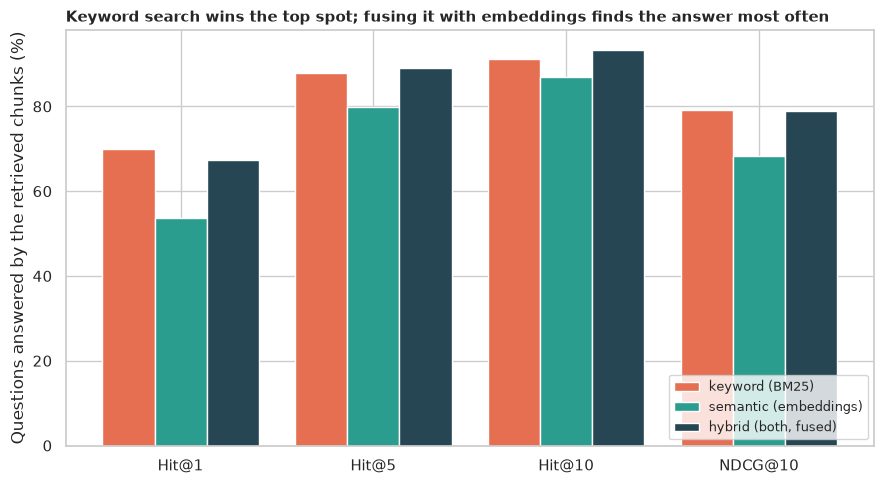

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(4)
for k, (method, color) in enumerate(zip(board.index, [ORANGE, TEAL, NAVY], strict=True)):
    values = [board.loc[method, m] * 100 for m in ("Hit@1", "Hit@5", "Hit@10", "NDCG@10")]
    ax.bar(x + (k - 1) * 0.27, values, 0.27, color=color, label=method)
ax.set_xticks(x, ["Hit@1", "Hit@5", "Hit@10", "NDCG@10"])
ax.set_ylabel("Questions answered by the retrieved chunks (%)")
ax.set_title(
    "Keyword search wins the top spot; fusing it with embeddings finds the answer most often",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_retrieval_methods.png", dpi=150)
plt.show()

**How to read this:**

| Search | MRR@10 | Hit@1 | Hit@5 | Hit@10 | NDCG@10 |
|---|---|---|---|---|---|
| Keyword (BM25) | **0.777** | **0.699** | 0.879 | 0.912 | **0.791** |
| Semantic (embeddings) | 0.651 | 0.537 | 0.799 | 0.869 | 0.683 |
| Hybrid (fused) | 0.766 | 0.673 | **0.891** | **0.934** | 0.788 |

- **Keyword search beats the embeddings here:** MRR **0.777** (95% CI 0.764 to 0.788) against **0.651** (0.638 to 0.664), a difference of **-0.126** for semantic (CI -0.141 to -0.110, Wilcoxon p = 6e-54). The right chunk is first for BM25 and not for the embeddings in 748 questions and the other way round in 261 (McNemar p = 5e-55). **We reject H₀**, in the direction opposite to the usual claim.
- **Fusing the two rescues the embeddings and finds more answers deep in the list:** hybrid beats semantic search by **+0.115** MRR (p = 3e-80) and has the best Hit@5 (**0.891**) and Hit@10 (**0.934**), but it is **slightly behind BM25 at first place** (MRR -0.011, CI -0.021 to -0.001, p = 0.03; Hit@1 0.673 against 0.699).
- **Why does BM25 win?** SQuAD questions were written by people *reading the paragraph*, so they reuse its rare words, which is exactly what BM25 rewards; MiniLM is also a small, general model. In a setting where users ask in their own words, the ranking would likely change; the safe lesson is to **measure on your own questions** and to **try the hybrid**, which is never far from the best.

## 8. H2: how big should a chunk be, and should chunks overlap?

*What:* semantic search over the four window sizes (50, 100, 200, 400 words, all with 20% overlap) and over 100-word windows with and without overlap. We choose the setting that wins on the tuning half of the questions and report it on the test half, run a Friedman test over the four sizes on the test half and bootstrap the differences against 100-word windows. *Why:* chunk size is the first knob everybody turns in a RAG system; the right value is a trade-off.

In [7]:
tune = (queries["half"] == "tune").to_numpy()
test = ~tune
rows = []
for name in CHUNKERS:
    for method in ("semantic (embeddings)", "keyword (BM25)"):
        s = scores[(name, method)]
        rows.append(
            {
                "chunking": name,
                "method": method,
                "mean words": corpora[name]["text"].str.split().str.len().mean(),
                "answer reachable": reachable[name],
                "MRR tune half": s["rr"][tune].mean(),
                "MRR test half": s["rr"][test].mean(),
                "Hit@5 test half": s["hit5"][test].mean(),
                "NDCG@10 test half": s["ndcg"][test].mean(),
            }
        )
chunk_table = pd.DataFrame(rows)
shown = chunk_table[chunk_table["method"] == "semantic (embeddings)"].set_index("chunking")
print("Semantic search, by how the documents are cut:")
print(shown.drop(columns="method").round(3).to_string())
best = shown["MRR tune half"].idxmax()
print(
    f"\nBest setting on the tuning half: {best}; on the test half its MRR is "
    f"{shown.loc[best, 'MRR test half']:.3f}"
)
window_names = [n for n in CHUNKERS if "windows, 20%" in n]
rr_matrix = np.stack(
    [scores[(n, "semantic (embeddings)")]["rr"].to_numpy()[test] for n in window_names]
)
fr = stats.friedmanchisquare(*rr_matrix)
print(
    f"Friedman test across the four window sizes on the test half: chi2 = {fr.statistic:.1f}, "
    f"p = {fmt_p(fr.pvalue)}"
)
for n in window_names:
    d = (
        scores[(n, "semantic (embeddings)")]["rr"].to_numpy()[test]
        - scores[(BASE, "semantic (embeddings)")]["rr"].to_numpy()[test]
    )
    if n != BASE:
        low, high = bootstrap_ci(d)
        print(
            f"  {n} minus the 100-word windows: MRR {d.mean():+.3f} (95% CI {low:+.3f} to "
            f"{high:+.3f})"
        )
nov = scores[("100-word windows, no overlap", "semantic (embeddings)")]["rr"].to_numpy()[test]
ov = scores[(BASE, "semantic (embeddings)")]["rr"].to_numpy()[test]
low, high = bootstrap_ci(ov - nov)
print(
    f"Overlap of 20% minus no overlap (100 words): MRR {np.mean(ov - nov):+.3f} "
    f"(95% CI {low:+.3f} to {high:+.3f}); answers reachable {reachable[BASE]:.1%} vs "
    f"{reachable['100-word windows, no overlap']:.1%}"
)

Semantic search, by how the documents are cut:
                                  mean words  answer reachable  MRR tune half  MRR test half  Hit@5 test half  NDCG@10 test half
chunking                                                                                                                        
50-word windows, 20% overlap          49.849             0.995          0.624          0.623            0.780              0.652
100-word windows, 20% overlap         99.346             1.000          0.648          0.653            0.803              0.685
200-word windows, 20% overlap        197.349             1.000          0.622          0.648            0.809              0.682
400-word windows, 20% overlap        389.853             1.000          0.525          0.528            0.682              0.551
100-word windows, no overlap          98.937             0.978          0.594          0.617            0.760              0.669
whole sentences, about 100 words      85.344      

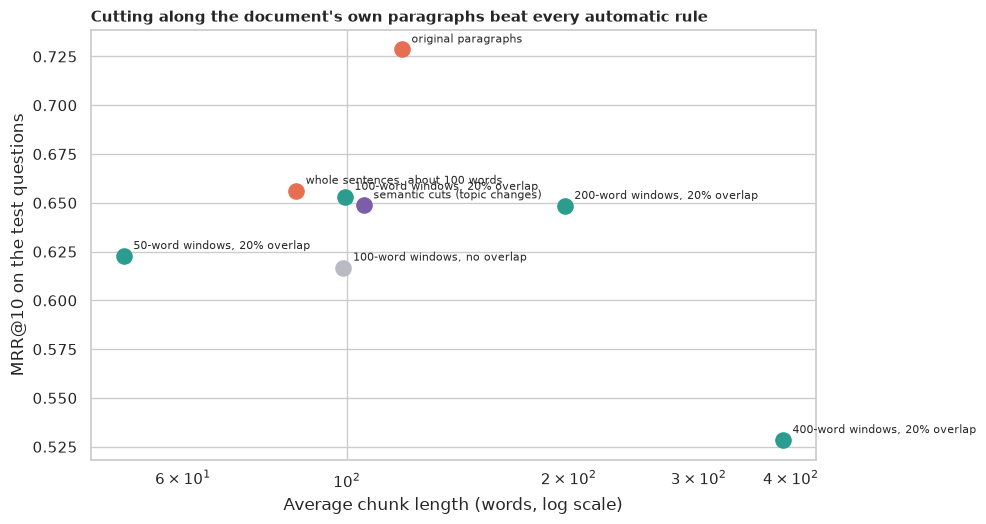

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.4))
for name, row in shown.iterrows():
    color = (
        TEAL
        if "windows, 20%" in name
        else PURPLE
        if "semantic" in name
        else ORANGE
        if "sentences" in name or "paragraphs" in name
        else GREY
    )
    ax.scatter(row["mean words"], row["MRR test half"], s=120, color=color, zorder=3)
    ax.annotate(
        name,
        (row["mean words"], row["MRR test half"]),
        textcoords="offset points",
        xytext=(7, 5),
        fontsize=8,
    )
ax.set_xscale("log")
ax.set_xlabel("Average chunk length (words, log scale)")
ax.set_ylabel("MRR@10 on the test questions")
ax.set_title(
    "Cutting along the document's own paragraphs beat every automatic rule",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_chunking.png", dpi=150)
plt.show()

**How to read this:**

- **There is a sweet spot around 100 to 200 words:** MRR on the test half is **0.623** for 50-word windows, **0.653** for 100, **0.648** for 200 and **0.528** for 400 (Friedman test across sizes: chi-square 68, p = 1e-14). **We reject H₀.**
- **Small chunks lose context, huge chunks drown the answer:** 50-word windows are **0.030** MRR worse than 100 (95% CI -0.050 to -0.010); 400-word windows are **0.125** worse (CI -0.150 to -0.101), and 200 words is no different from 100 (-0.005, CI -0.023 to +0.013).
- **Overlap pays for itself:** 100-word windows with 20% overlap beat the same windows without overlap by **+0.036** MRR (CI +0.019 to +0.052), and keep 100.0% of the answers whole (97.8% without).
- **The tuning half chose the original paragraphs** (MRR 0.713), whose test-half MRR is **0.729**: the best value in the table; see H3.

## 9. H3: is semantic chunking worth it?

*What:* compare four cutters of about the same size, using semantic search: fixed 100-word windows, whole sentences packed to about 100 words, the original paragraphs and the semantic cuts (cut where the topic changes). We compare each against the fixed windows with a Wilcoxon test and a bootstrap interval. *Why:* "semantic chunking" sounds smarter than a plain word window and costs an embedding pass over every sentence.

In [9]:
compare = [
    "100-word windows, 20% overlap",
    "whole sentences, about 100 words",
    "original paragraphs",
    "semantic cuts (topic changes)",
]
rows = []
for name in compare:
    s = scores[(name, "semantic (embeddings)")]
    low, high = bootstrap_ci(s["rr"].to_numpy())
    rows.append(
        {
            "chunking": name,
            "mean words": corpora[name]["text"].str.split().str.len().mean(),
            "chunks": len(corpora[name]),
            "answer reachable": reachable[name],
            "MRR@10": s["rr"].mean(),
            "MRR 95% CI": f"{low:.3f} to {high:.3f}",
            "Hit@5": s["hit5"].mean(),
            "NDCG@10": s["ndcg"].mean(),
        }
    )
print(pd.DataFrame(rows).set_index("chunking").round(3).to_string())
base_rr = scores[("100-word windows, 20% overlap", "semantic (embeddings)")]["rr"].to_numpy()
for name in compare[1:]:
    d = scores[(name, "semantic (embeddings)")]["rr"].to_numpy() - base_rr
    low, high = bootstrap_ci(d)
    wil = stats.wilcoxon(d[d != 0])
    print(
        f"{name} minus fixed windows: MRR {d.mean():+.3f} (95% CI {low:+.3f} to {high:+.3f}), "
        f"Wilcoxon p = {fmt_p(wil.pvalue)}"
    )
semantic_len = corpora["semantic cuts (topic changes)"]["text"].str.split().str.len()
print(
    f"\nSemantic chunks: {semantic_len.quantile(0.1):.0f} to {semantic_len.quantile(0.9):.0f} "
    f"words (10th to 90th percentile), median {semantic_len.median():.0f}"
)

                                  mean words  chunks  answer reachable  MRR@10      MRR 95% CI  Hit@5  NDCG@10
chunking                                                                                                      
100-word windows, 20% overlap         99.346    8006             1.000   0.651  0.636 to 0.666  0.799    0.683
whole sentences, about 100 words      85.344    7475             0.998   0.656  0.641 to 0.670  0.794    0.706
original paragraphs                  118.709    5374             1.000   0.721  0.707 to 0.735  0.852    0.765
semantic cuts (topic changes)        105.428    6051             0.998   0.649  0.634 to 0.663  0.806    0.703
whole sentences, about 100 words minus fixed windows: MRR +0.005 (95% CI -0.007 to +0.018), Wilcoxon p = 3.3e-01
original paragraphs minus fixed windows: MRR +0.070 (95% CI +0.058 to +0.083), Wilcoxon p = 3.6e-26
semantic cuts (topic changes) minus fixed windows: MRR -0.002 (95% CI -0.016 to +0.012), Wilcoxon p = 7.2e-01

Semantic c

**How to read this:**

- **Semantic cuts make no difference:** MRR **0.649** against **0.651** for fixed windows (difference -0.002, CI -0.016 to +0.012, p = 0.72), and the extra work cost an embedding of 27,028 sentences. Their chunks range from **47 to 185** words (10th to 90th percentile), median 93. **We do not reject H₀.**
- **Packing whole sentences does not help either:** MRR **0.656** (+0.005, CI -0.007 to +0.018, p = 0.33).
- **Cutting along the document's own paragraphs does:** MRR **0.721** (CI 0.707 to 0.735) against **0.651**, a gain of **+0.070** (CI +0.058 to +0.083, p = 4e-26), with Hit@5 0.852 against 0.799. **We reject H₀** for paragraphs.
- **Read the paragraph win with care:** the questions were written about *those paragraphs*, so a paragraph chunk lines up exactly with the question's source. Real documents may have no such structure (or messy, uneven paragraphs); the transferable lesson is that **respecting real structure beats cutting blindly or guessing topic changes**, and that no automatic cutter we tried reached it.

## 10. H4: fast approximate indexes (FAISS)

*What:* **FAISS** is a library for finding the nearest vectors. The simplest index (`Flat`) compares the question with **every** chunk and is exact. Approximate indexes skip most comparisons: **HNSW** hops through a graph of neighbouring vectors; **IVF** groups the vectors into cells and only searches the nearest few cells. We build each on the 8,006 chunk vectors and measure the share of the *exact* top 10 that it finds (recall) and the queries per second, for one query at a time and in a batch of 3,000. *Why:* at millions of chunks exact search is too slow; the question is what speed costs in lost answers.

In [10]:
base_vectors = chunk_vectors[BASE]
dim = base_vectors.shape[1]
exact_top = dense_search(indexes[BASE], question_vectors, 10)
rows = []


def evaluate_index(label: str, index: faiss.Index, build_seconds: float) -> None:
    """Records recall against exact search, and speed, for an index."""
    start = time.perf_counter()
    approx = index.search(question_vectors, 10)[1]
    batch_seconds = time.perf_counter() - start
    start = time.perf_counter()
    for i in range(200):
        index.search(question_vectors[i : i + 1], 10)
    single_seconds = time.perf_counter() - start
    recall = np.mean([len(set(a) & set(e)) / 10 for a, e in zip(approx, exact_top, strict=True)])
    rows.append(
        {
            "index": label,
            "recall of the exact top 10": recall,
            "queries per second (one by one)": 200 / single_seconds,
            "queries per second (batch)": N_QUERIES / batch_seconds,
            "build seconds": build_seconds,
        }
    )


evaluate_index("exact (Flat)", indexes[BASE], 0.0)
for m, ef in ((16, 16), (32, 16), (32, 64)):
    start = time.perf_counter()
    hnsw = faiss.IndexHNSWFlat(dim, m, faiss.METRIC_INNER_PRODUCT)
    hnsw.hnsw.efConstruction = 100
    hnsw.add(base_vectors)
    build = time.perf_counter() - start
    hnsw.hnsw.efSearch = ef
    evaluate_index(f"HNSW (links {m}, search width {ef})", hnsw, build)
for nprobe in (1, 4, 16):
    start = time.perf_counter()
    quantizer = faiss.IndexFlatIP(dim)
    ivf = faiss.IndexIVFFlat(quantizer, dim, 64, faiss.METRIC_INNER_PRODUCT)
    ivf.train(base_vectors)
    ivf.add(base_vectors)
    build = time.perf_counter() - start
    ivf.nprobe = nprobe
    evaluate_index(f"IVF (64 cells, search {nprobe})", ivf, build)
ann = pd.DataFrame(rows).set_index("index")
print(f"{len(base_vectors):,} chunk vectors of {dim} numbers each")
print(ann.round(3).to_string())

8,006 chunk vectors of 384 numbers each
                                  recall of the exact top 10  queries per second (one by one)  queries per second (batch)  build seconds
index                                                                                                                                   
exact (Flat)                                           1.000                         2243.563                   52871.870          0.000
HNSW (links 16, search width 16)                       0.947                        33011.744                  389136.553          0.148
HNSW (links 32, search width 16)                       0.959                        26994.794                  292315.778          0.150
HNSW (links 32, search width 64)                       0.996                        11959.668                  109004.720          0.145
IVF (64 cells, search 1)                               0.691                        45283.795                   25894.802          0.042
I

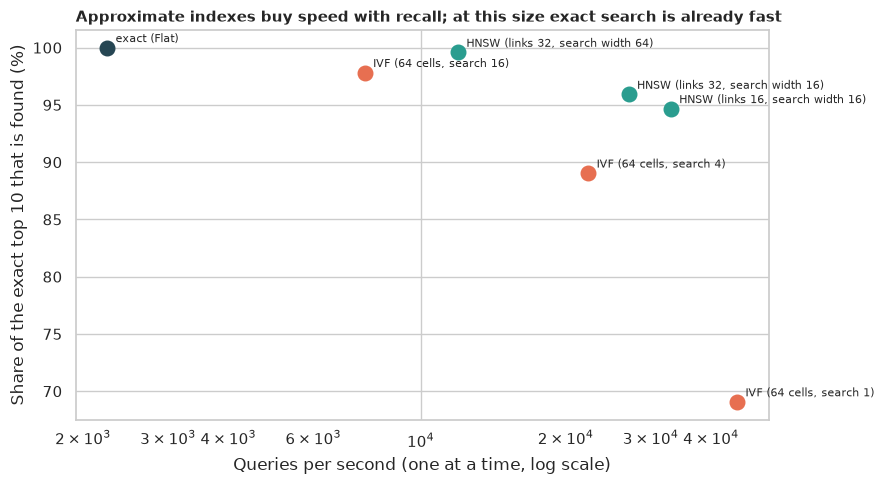

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, row in ann.iterrows():
    color = NAVY if "Flat" in name else TEAL if "HNSW" in name else ORANGE
    ax.scatter(
        row["queries per second (one by one)"],
        row["recall of the exact top 10"] * 100,
        s=110,
        color=color,
        zorder=3,
    )
    ax.annotate(
        name,
        (row["queries per second (one by one)"], row["recall of the exact top 10"] * 100),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=8,
    )
ax.set_xscale("log")
ax.set_xlabel("Queries per second (one at a time, log scale)")
ax.set_ylabel("Share of the exact top 10 that is found (%)")
ax.set_title(
    "Approximate indexes buy speed with recall; at this size exact search is already fast",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_ann_tradeoff.png", dpi=150)
plt.show()

**How to read this:**

- **Approximate indexes are much faster per query, at a price in recall:** exact search handles about **2,200** single queries per second; HNSW (16 links, search width 16) about **33,000** but finds only **94.7%** of the exact top 10; with more links and a wider search (32, 64) it finds **99.6%** at about **12,000** per second. IVF with 64 cells finds **69.1%** if it searches one cell (45,000 queries per second), **89.0%** with four cells and **97.8%** with 16 cells (7,700 per second).
- **The dial is explicit:** the more of the graph or cells you search, the closer to exact and the slower you go.
- **At this size exact search is already fast enough:** 8,006 vectors fit in memory and a batch of 3,000 questions takes under 0.1 second (about **53,000** per second); the batch speed of IVF (26,000 to 38,000) is even lower. The benefits of ANN appear at **millions** of vectors, which this corpus is far from; the recall losses, on the other hand, are already visible here. **We reject H₀:** approximate indexes do lose some of the exact top 10.

## 11. H5: from search to answer

*What:* give a **reader** (RoBERTa fine-tuned on SQuAD 2.0) the chunks that the hybrid search returns for 1,000 test questions and ask it for the answer. The reader reads the top **1, 3 or 5** chunks separately and the answer with the best score wins. Two **oracles** show the ceiling: the reader given the **one correct chunk**, and given the **original SQuAD paragraph**. We measure exact match and F1 against the reference answers, and compare the answer quality when the right chunk was among the top 5 and when it was not. *Why:* this is the RAG question: how much does answer quality depend on retrieval?

In [12]:
reader_tok = AutoTokenizer.from_pretrained(READER)
reader = AutoModelForQuestionAnswering.from_pretrained(READER).to(DEVICE).eval()


def read(questions: list[str], contexts: list[str]) -> tuple[list[str], np.ndarray]:
    """The best answer span for each (question, chunk) pair and its score.

    Args:
        questions: The questions.
        contexts: The chunk each question is read against.

    Returns:
        The answer text and the span score (start plus end logit) of each pair.
    """
    enc = reader_tok(
        questions,
        contexts,
        truncation="only_second",
        max_length=384,
        stride=128,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length",
    )
    starts, ends = [], []
    with torch.no_grad():
        for i in range(0, len(enc["input_ids"]), 32):
            out = reader(
                input_ids=torch.tensor(enc["input_ids"][i : i + 32], device=DEVICE),
                attention_mask=torch.tensor(enc["attention_mask"][i : i + 32], device=DEVICE),
            )
            starts.append(out.start_logits.float().cpu().numpy())
            ends.append(out.end_logits.float().cpu().numpy())
    starts, ends = np.concatenate(starts), np.concatenate(ends)
    best = np.full(len(questions), -np.inf)
    text = [""] * len(questions)
    for f in range(len(starts)):
        q = enc["overflow_to_sample_mapping"][f]
        in_context = np.array([s == 1 for s in enc.sequence_ids(f)])
        for a in np.argsort(starts[f])[-10:]:
            for b in np.argsort(ends[f])[-10:]:
                if in_context[a] and in_context[b] and a <= b < a + 30:
                    score = starts[f][a] + ends[f][b]
                    if score > best[q]:
                        best[q] = score
                        text[q] = contexts[q][
                            enc["offset_mapping"][f][a][0] : enc["offset_mapping"][f][b][1]
                        ]
    return text, best


def normalise(text: str) -> str:
    """The official SQuAD answer normalisation: lower-case, no punctuation, no articles."""
    text = "".join(ch for ch in text.lower() if ch not in set("!\"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~"))
    return " ".join(re.sub(r"\b(a|an|the)\b", " ", text).split())


def exact_and_f1(prediction: str, golds: list[str]) -> tuple[float, float]:
    """Exact match and word-overlap F1 against the best reference answer."""
    em, best = 0.0, 0.0
    for gold in golds:
        p, g = normalise(prediction).split(), normalise(gold).split()
        em = max(em, float(p == g))
        common = sum(min(p.count(w), g.count(w)) for w in set(p))
        if common:
            precision, recall = common / len(p), common / len(g)
            best = max(best, 2 * precision * recall / (precision + recall))
    return em, best


reader_rows = np.flatnonzero(test)[:N_READER_QUERIES]
sub_queries = queries.iloc[reader_rows]
chunks = corpora[BASE]["text"].tolist()
ranked = retrievers[(BASE, "hybrid (both, fused)")][reader_rows]
rel = [relevant[BASE][i] for i in reader_rows]
results = {}
for k in (1, 3, 5):
    questions = [q for q in sub_queries["query"] for _ in range(k)]
    contexts = [chunks[c] for row in ranked for c in row[:k]]
    answers, span_scores = read(questions, contexts)
    chosen = []
    for i in range(len(sub_queries)):
        block = slice(i * k, (i + 1) * k)
        chosen.append(answers[block][int(np.argmax(span_scores[block]))])
    results[f"top {k} retrieved chunks"] = chosen
oracle_chunks = [chunks[r[0]] if len(r) else "" for r in rel]
gold_answers, _ = read(sub_queries["query"].tolist(), oracle_chunks)
results["the correct chunk (oracle)"] = gold_answers
results["the original SQuAD paragraph (oracle)"] = read(
    sub_queries["query"].tolist(), sub_queries["context"].tolist()
)[0]
rows = []
for name, answers in results.items():
    em_f1 = np.array(
        [exact_and_f1(a, g) for a, g in zip(answers, sub_queries["answers"], strict=True)]
    )
    low, high = bootstrap_ci(em_f1[:, 1])
    rows.append(
        {
            "reader sees": name,
            "exact match": em_f1[:, 0].mean(),
            "F1": em_f1[:, 1].mean(),
            "F1 95% CI": f"{low:.3f} to {high:.3f}",
        }
    )
    results[name] = (answers, em_f1)
rag = pd.DataFrame(rows).set_index("reader sees")
print(
    f"{len(sub_queries):,} test questions, answered by RoBERTa (SQuAD 2.0) from the chunks the "
    f"hybrid search returns ({BASE})"
)
print(rag.round(3).to_string())
top5_f1 = results["top 5 retrieved chunks"][1][:, 1]
found = np.array([bool(np.isin(ranked[i][:5], rel[i]).any()) for i in range(len(sub_queries))])
print(
    f"\nWhen a relevant chunk is among the top 5 ({found.mean():.1%} of questions): F1 "
    f"{top5_f1[found].mean():.3f}; when it is not: F1 {top5_f1[~found].mean():.3f}"
)
mw = stats.mannwhitneyu(top5_f1[found], top5_f1[~found])
print(f"Mann-Whitney p = {fmt_p(mw.pvalue)}")

1,000 test questions, answered by RoBERTa (SQuAD 2.0) from the chunks the hybrid search returns (100-word windows, 20% overlap)
                                       exact match     F1       F1 95% CI
reader sees                                                              
top 1 retrieved chunks                       0.599  0.663  0.632 to 0.694
top 3 retrieved chunks                       0.683  0.751  0.727 to 0.775
top 5 retrieved chunks                       0.702  0.771  0.745 to 0.795
the correct chunk (oracle)                   0.823  0.895  0.878 to 0.911
the original SQuAD paragraph (oracle)        0.834  0.908  0.892 to 0.922

When a relevant chunk is among the top 5 (89.7% of questions): F1 0.846; when it is not: F1 0.114
Mann-Whitney p = 5.1e-60


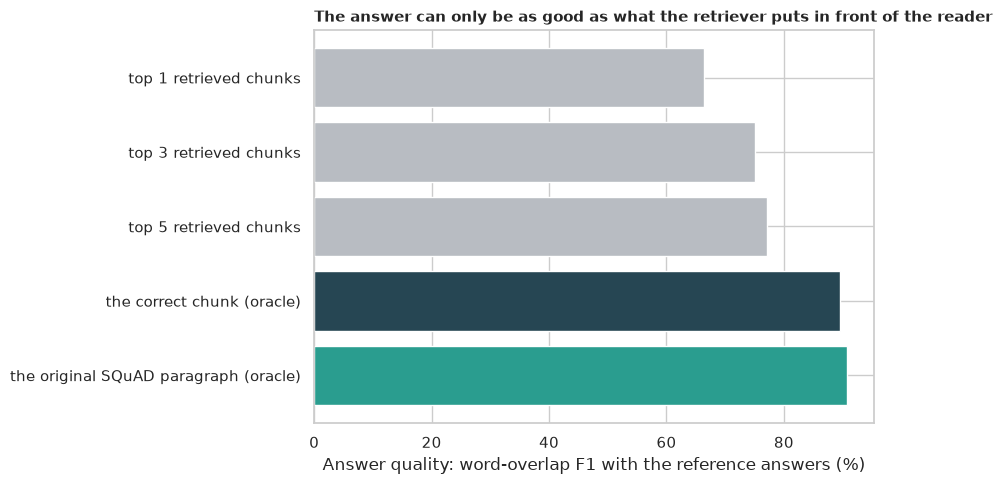

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
order = list(rag.index)
colors = [GREY] * 3 + [NAVY, TEAL]
ax.barh(range(len(order)), rag["F1"] * 100, color=colors[: len(order)])
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_xlabel("Answer quality: word-overlap F1 with the reference answers (%)")
ax.set_title(
    "The answer can only be as good as what the retriever puts in front of the reader",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_end_to_end.png", dpi=150)
plt.show()

**How to read this:**

| The reader sees | Exact match | F1 (95% CI) |
|---|---|---|
| top 1 retrieved chunk | 0.599 | 0.663 (0.632 to 0.694) |
| top 3 retrieved chunks | 0.683 | 0.751 (0.727 to 0.775) |
| top 5 retrieved chunks | 0.702 | 0.771 (0.745 to 0.795) |
| the correct chunk (oracle) | 0.823 | 0.895 (0.878 to 0.911) |
| the original SQuAD paragraph (oracle) | 0.834 | 0.908 (0.892 to 0.922) |

- **More retrieved chunks mean better answers, with diminishing returns:** F1 goes from **0.663** (1 chunk) to **0.751** (3) and **0.771** (5), because the correct chunk is more often among them.
- **There is still a gap to the oracle:** with the correct chunk the reader reaches **0.895**, **0.124 above** the top-5 result; the original paragraph gives 0.908 (a small extra 0.013 for the paragraph's cleaner start).
- **Retrieval decides everything:** when a relevant chunk is among the top 5 (**89.7%** of the questions) the F1 is **0.846**; when it is not, it is **0.114** (Mann-Whitney p = 5e-60). The reader is not the bottleneck: **the answer is almost always right when the right page is on the table, and almost never otherwise.** **We reject H₀.**

## 12. 🎯 Takeaways

1. **Retrieval is the ceiling of RAG:** answer F1 is 0.846 when the right chunk is among the top 5 and 0.114 when it is not.
2. **Never assume vector search beats keywords:** on this benchmark BM25 has MRR 0.777 against 0.651 for MiniLM embeddings (and the questions reuse the paragraphs' words, which favours BM25). **Measure on your own questions.**
3. **Hybrid search is the safe default:** fusing both gives the best Hit@5 (0.891) and Hit@10 (0.934), rescuing the weaker retriever.
4. **Chunk size has a sweet spot (100 to 200 words):** 50 words lose context (-0.030 MRR), 400 words drown the answer (-0.125).
5. **Use overlap:** +0.036 MRR and no answers cut in half (100.0% reachable against 97.8%).
6. **"Semantic chunking" did not pay:** MRR 0.649 against 0.651 for fixed windows, after embedding all 27,028 sentences; respecting the real paragraphs gave +0.070.
7. **Approximate indexes trade recall for speed:** HNSW at 94.7% recall is 15 times faster than exact search, at 99.6% only 5 times; at 8,000 chunks you do not need either.
8. **Evaluate with ground truth:** Hit@k, MRR and NDCG on questions with known answers turn "it seems to work" into a number.

## 13. ⚠️ Limitations

- **SQuAD questions were written while looking at the paragraph,** so they share rare words with their answers; this favours BM25 and the paragraph chunks. Natural user questions are usually less lexical, and the ranking of retrievers could change.
- **One small embedding model** (MiniLM, 384 numbers) and one reader (RoBERTa-base). Larger or retrieval-trained models (and re-rankers) would narrow or reverse the gap with BM25.
- **A 135-document library of 8,000 chunks** is tiny: the speed results for approximate indexes do not predict behaviour at millions of vectors, and distractor articles are about different topics from the questions.
- **One answer per question, found by string position:** a chunk that says the same thing in other words, or that contains the answer string by accident, is scored as it falls.
- **Relevance means "contains the whole answer text",** which is stricter than "helps a reader"; and one-hit questions ignore chunks that give partial evidence.
- **No generation step:** the reader extracts an answer span; a generative language model could use the chunks differently (and hallucinate in ways we do not measure).
- **The chunking settings were tried one at a time,** with fixed overlap (20%) and fixed semantic-cut parameters (30th percentile, 40 to 200 words), not tuned jointly.
- **The tuning and test halves come from the same articles,** so the choice of setting is not tested on unseen documents.
- **Reciprocal rank fusion uses its standard constant (60) untuned.**